# 03. Minería de patrones de lectura (Proyecto B)

Tres preguntas sobre el dataset abierto **Goodbooks-10k** (10.000 libros, unos 6 millones
de valoraciones de 53.424 usuarios y las etiquetas que los lectores les pusieron):

1. **Reglas de asociación:** ¿qué géneros y qué libros se leen juntos?
2. **Agrupamiento (clustering):** si se agrupan los libros solo por *quién los lee*,
   ¿los grupos se parecen a la clasificación por género?
3. **Árbol de decisión:** ¿se puede adivinar el género de un libro con datos que no
   son sus etiquetas (año, nota media, popularidad)?

Antes de ejecutar: `python src/descargar_goodbooks.py` desde la raíz del repo.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from src.mineria import (
    GENEROS, cargar_goodbooks, generos_por_libro, cestas_de_generos, apriori,
    reglas_de_asociacion, reglas_entre_libros, vectores_por_lectores, atributos_para_arbol,
)

pd.set_option("display.max_colwidth", 60)
datos = cargar_goodbooks("../data")
for nombre, tabla in datos.items():
    print(f"{nombre}: {tabla.shape[0]:,} filas x {tabla.shape[1]} columnas")

libros: 10,000 filas x 23 columnas
valoraciones: 5,976,479 filas x 3 columnas
etiquetas: 34,252 filas x 2 columnas
etiquetas_libro: 999,912 filas x 3 columnas


## 1. Un género para cada libro

Goodbooks no trae una clasificación oficial (ni Dewey ni LCC). Lo que trae son
*etiquetas* libres de los lectores: `fantasy`, `sci-fi`, `to-read`, `owned`...
Es una folksonomía: hay sinónimos (`sci-fi`, `scifi`, `science-fiction`) y mucho
ruido (`to-read` no dice nada del contenido).

El paso de control de vocabulario está en `src/mineria.py`: el diccionario `GENEROS`
agrupa a mano los sinónimos en 16 géneros. El **género principal** de un libro es
el que concentra más usos de sus etiquetas de género.

Géneros definidos: 16 | etiquetas agrupadas: 120


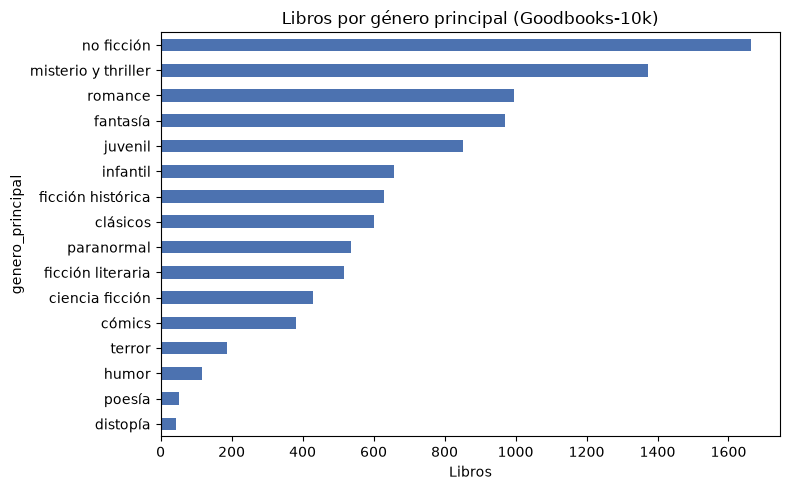

genero_principal,no ficción,misterio y thriller,romance,fantasía,juvenil,infantil,ficción histórica,clásicos,paranormal,ficción literaria,ciencia ficción,cómics,terror,humor,poesía,distopía
libros,1662,1373,997,969,852,658,628,600,535,516,430,381,188,118,51,42


In [2]:
generos = generos_por_libro(datos)
print("Géneros definidos:", len(GENEROS), "| etiquetas agrupadas:", sum(len(v) for v in GENEROS.values()))

conteo = generos["genero_principal"].value_counts()
ax = conteo.sort_values().plot.barh(figsize=(8, 5), color="#4C72B0")
ax.set_xlabel("Libros")
ax.set_title("Libros por género principal (Goodbooks-10k)")
plt.tight_layout()
plt.show()
conteo.to_frame("libros").T

In [3]:
# Comprobación a ojo: los cinco libros más populares de algunos géneros
titulos = datos["libros"].set_index("book_id")["title"]
for g in ["fantasía", "clásicos", "no ficción", "ficción literaria"]:
    ids = generos.index[generos["genero_principal"] == g][:5]
    print(f"{g}: " + " | ".join(titulos.loc[ids].str.slice(0, 32)))

fantasía: Harry Potter and the Sorcerer's  | The Hobbit | Harry Potter and the Prisoner of | The Fellowship of the Ring (The  | Harry Potter and the Chamber of 
clásicos: To Kill a Mockingbird | The Great Gatsby | The Catcher in the Rye | Pride and Prejudice | Animal Farm
no ficción: The Diary of a Young Girl | The Alchemist | Eat, Pray, Love | The Glass Castle | Into the Wild
ficción literaria: Jane Eyre | Life of Pi | Sense and Sensibility | The Memory Keeper's Daughter | Middlesex


La asignación es razonable pero no perfecta: *El alquimista* queda en no ficción
(sus etiquetas dominantes son `philosophy` y `spirituality`) y *Jane Eyre* en
ficción literaria en vez de clásicos. Es el costo de derivar la clasificación de
etiquetas libres, y afecta a todo lo que sigue.

## 2. Reglas de asociación entre géneros

Cada usuario es una "cesta". Un género entra en su cesta si al menos el 10% de los
libros que valoró con 4 o 5 estrellas son de ese género. Sobre esas cestas corre un
**Apriori escrito a mano** (`apriori` en `src/mineria.py`) con soporte mínimo de 3%.

Tres medidas por regla *A → B*:
- **soporte:** proporción de usuarios que tienen A y B.
- **confianza:** de los usuarios con A, cuántos tienen B.
- **lift:** confianza dividida por la frecuencia de B. Sobre 1, A y B aparecen
  juntos más de lo esperable por azar; bajo 1, se "repelen".

In [4]:
cestas = cestas_de_generos(datos, generos, nota_minima=4, peso_minimo=0.10)
print(f"Usuarios: {len(cestas):,} | géneros por cesta (media): {cestas.sum(axis=1).mean():.2f}")

frecuentes = apriori(cestas, soporte_minimo=0.03, tamano_maximo=3)
reglas = reglas_de_asociacion(frecuentes, confianza_minima=0.30)
print(f"Conjuntos frecuentes: {len(frecuentes)} | reglas: {len(reglas)}")
reglas.head(12).round(3)

Usuarios: 53,406 | géneros por cesta (media): 3.25
Conjuntos frecuentes: 78 | reglas: 87


,antecedente,consecuente,soporte,confianza,lift
0,ficción literaria + misterio y thriller,ficción histórica,0.046,0.746,2.614
1,ficción histórica + no ficción,ficción literaria,0.071,0.433,2.527
2,clásicos + ficción histórica,ficción literaria,0.054,0.402,2.350
3,ficción histórica,ficción literaria,0.109,0.380,2.219
4,ficción literaria,ficción histórica,0.109,0.634,2.219
5,ficción literaria + no ficción,ficción histórica,0.071,0.622,2.177
6,ficción histórica + misterio y thriller,ficción literaria,0.046,0.340,1.988
7,paranormal,juvenil,0.067,0.558,1.877
8,fantasía + paranormal,juvenil,0.035,0.549,1.849
9,clásicos + ficción literaria,ficción histórica,0.054,0.523,1.833


In [5]:
# Reglas con un solo género de antecedente, y las que más se "repelen" (lift < 1)
simples = reglas[~reglas["antecedente"].str.contains(r"\+")]
display(simples.head(8).round(3))
reglas.tail(5).round(3)

,antecedente,consecuente,soporte,confianza,lift
3,ficción histórica,ficción literaria,0.109,0.380,2.219
4,ficción literaria,ficción histórica,0.109,0.634,2.219
7,paranormal,juvenil,0.067,0.558,1.877
10,terror,misterio y thriller,0.035,0.632,1.828
12,paranormal,romance,0.038,0.315,1.689
15,ficción literaria,no ficción,0.115,0.669,1.583
18,romance,juvenil,0.086,0.460,1.549
19,ciencia ficción,fantasía,0.100,0.681,1.521


,antecedente,consecuente,soporte,confianza,lift
82,misterio y thriller,fantasía,0.118,0.341,0.762
83,clásicos + misterio y thriller,fantasía,0.042,0.340,0.759
84,infantil + no ficción,fantasía,0.033,0.330,0.738
85,ficción histórica + misterio y thriller,clásicos,0.044,0.331,0.730
86,ciencia ficción + fantasía,no ficción,0.031,0.307,0.726


In [6]:
# Verificación: el Apriori propio debe dar lo mismo que mlxtend (si está instalado)
try:
    from mlxtend.frequent_patterns import apriori as apriori_mlxtend
    ref = apriori_mlxtend(cestas, min_support=0.03, use_colnames=True, max_len=3)
    ref = {frozenset(c): s for c, s in zip(ref["itemsets"], ref["support"])}
    iguales = set(ref) == set(frecuentes)
    dif = max(abs(ref[c] - frecuentes[c]) for c in ref) if iguales else float("nan")
    print(f"mlxtend: {len(ref)} conjuntos | mismos conjuntos: {iguales} | diferencia máxima de soporte: {dif:.2e}")
except ImportError:
    print("mlxtend no está instalado; se omite la verificación (pip install mlxtend).")

mlxtend no está instalado; se omite la verificación (pip install mlxtend).


**Lectura de las reglas de géneros**

- La asociación más fuerte es **ficción literaria ↔ ficción histórica** (lift 2,2):
  el 63% de quienes leen ficción literaria también leen ficción histórica, cuando
  en el total de usuarios es el 29%.
- **Paranormal → juvenil** (lift 1,9) y **terror → misterio y thriller** (lift 1,8)
  son los otros dos vínculos claros.
- Las reglas con lift menor que 1 muestran públicos que se cruzan poco: quien lee
  misterio y thriller lee fantasía menos de lo esperable (lift 0,76).

## 3. Reglas de asociación entre libros

La misma idea a nivel de título: la cesta de cada usuario son los libros que valoró
con 4 o 5 estrellas. Solo pares que al menos el 2% de los usuarios comparten.

In [7]:
pares = reglas_entre_libros(datos, nota_minima=4, soporte_minimo=0.02)
print(f"Pares con soporte >= 2%: {len(pares):,} | del mismo autor: {pares['mismo_autor'].mean():.1%}")
columnas = ["title_a", "title_b", "soporte", "confianza_a_b", "lift"]
pares[columnas].head(5).round(3)

Pares con soporte >= 2%: 4,326 | del mismo autor: 7.7%


,title_a,title_b,soporte,confianza_a_b,lift
0,"From Dead to Worse (Sookie Stackhouse, #8)","Dead and Gone (Sookie Stackhouse, #9)",0.021,0.839,34.645
1,"All Together Dead (Sookie Stackhouse, #7)","From Dead to Worse (Sookie Stackhouse, #8)",0.022,0.815,33.119
2,"Definitely Dead (Sookie Stackhouse, #6)","From Dead to Worse (Sookie Stackhouse, #8)",0.021,0.808,32.835
3,"Dead as a Doornail (Sookie Stackhouse, #5)","Definitely Dead (Sookie Stackhouse, #6)",0.023,0.866,32.679
4,"Dead as a Doornail (Sookie Stackhouse, #5)","From Dead to Worse (Sookie Stackhouse, #8)",0.021,0.788,31.990


In [8]:
# Lo interesante: pares de autores distintos
otros = pares[~pares["mismo_autor"]]
otros = otros.join(generos["genero_principal"].rename("genero_a"), on="libro_a")
otros = otros.join(generos["genero_principal"].rename("genero_b"), on="libro_b")
mismo_genero = otros["genero_a"] == otros["genero_b"]
print(f"Pares de autores distintos: {len(otros):,}")
print(f"  comparten género principal (todos): {mismo_genero.mean():.1%}")
print(f"  comparten género principal (200 de mayor lift): {mismo_genero.head(200).mean():.1%}")
display(otros[columnas].head(10).round(3))
otros[~mismo_genero][columnas + ["genero_a", "genero_b"]].head(8).round(3)

Pares de autores distintos: 3,992
  comparten género principal (todos): 24.5%
  comparten género principal (200 de mayor lift): 65.5%


,title_a,title_b,soporte,confianza_a_b,lift
168,The Very Hungry Caterpillar Board Book,Goodnight Moon,0.021,0.455,8.933
196,"The Name of the Wind (The Kingkiller Chronicle, #1)","The Final Empire (Mistborn, #1)",0.021,0.322,7.614
206,The Nightingale,Orphan Train,0.021,0.343,7.170
220,Big Little Lies,The Nightingale,0.022,0.394,6.340
235,All the Light We Cannot See,The Nightingale,0.035,0.358,5.773
237,Dune (Dune Chronicles #1),Foundation (Foundation #1),0.021,0.246,5.719
242,Green Eggs and Ham,Goodnight Moon,0.022,0.283,5.561
244,All the Light We Cannot See,The Invention of Wings,0.022,0.232,5.448
249,"Me Before You (Me Before You, #1)",The Husband's Secret,0.024,0.265,5.288
250,Where the Wild Things Are,Goodnight Moon,0.026,0.269,5.280


,title_a,title_b,soporte,confianza_a_b,lift,genero_a,genero_b
220,Big Little Lies,The Nightingale,0.022,0.394,6.340,misterio y thriller,ficción histórica
249,"Me Before You (Me Before You, #1)",The Husband's Secret,0.024,0.265,5.288,romance,misterio y thriller
256,"Me Before You (Me Before You, #1)",Big Little Lies,0.025,0.283,5.090,romance,misterio y thriller
264,"Me Before You (Me Before You, #1)",Orphan Train,0.021,0.237,4.956,romance,ficción histórica
273,The Joy Luck Club,Divine Secrets of the Ya-Ya Sisterhood,0.022,0.275,4.692,clásicos,romance
275,My Sister's Keeper,The Memory Keeper's Daughter,0.022,0.249,4.649,romance,ficción literaria
278,The Secret Life of Bees,The Memory Keeper's Daughter,0.027,0.247,4.624,ficción histórica,ficción literaria
280,"Me Before You (Me Before You, #1)",The Nightingale,0.026,0.287,4.616,romance,ficción histórica


**Lectura de las reglas de libros**

- Los pares de mayor lift son tomos de una misma saga (Sookie Stackhouse, lift 30+):
  cierto, pero obvio. Por eso se separan los pares de **autores distintos**.
- Entre autores distintos aparecen recomendaciones reales: *El nombre del viento* con
  *El imperio final* (lift 7,6), *Dune* con *Fundación* (lift 5,7), y un bloque de
  libros infantiles ilustrados.
- **Las afinidades cruzan los géneros.** De los 200 pares de autores distintos con
  más lift, el 65,5% comparte género principal; en el total de pares, solo el 24,5%.
  Pares como *Big Little Lies* (thriller) y *El ruiseñor* (ficción histórica) unen
  géneros distintos con un mismo público. Una estantería por género no los pondría juntos.

## 4. Agrupamiento por lectores frente a la clasificación por género

Cada libro se representa por **quiénes lo leyeron** (matriz libros × usuarios,
reducida a 50 dimensiones con SVD). Las etiquetas no intervienen. Luego K-means
arma grupos y se comparan con el género principal.

Medidas de coincidencia: **pureza** (proporción de libros cuyo género es el
mayoritario de su grupo), **ARI** y **NMI** (0 = coincidencia al azar, 1 = idéntico).

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

vectores, ids_libros = vectores_por_lectores(datos, componentes=50, semilla=42)
genero_real = generos["genero_principal"].loc[ids_libros].to_numpy()

filas = []
for k in [8, 12, 16, 20, 30]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(vectores)
    tabla = pd.crosstab(km.labels_, genero_real)
    filas.append({
        "k": k,
        "silueta": silhouette_score(vectores, km.labels_, sample_size=3000, random_state=0),
        "pureza": tabla.max(axis=1).sum() / len(genero_real),
        "ARI": adjusted_rand_score(genero_real, km.labels_),
        "NMI": normalized_mutual_info_score(genero_real, km.labels_),
    })
pd.DataFrame(filas).set_index("k").round(3)

,silueta,pureza,ARI,NMI
k,,,,
8,0.133,0.482,0.275,0.435
12,0.140,0.539,0.295,0.469
16,0.174,0.553,0.286,0.480
20,0.195,0.602,0.287,0.501
30,0.231,0.633,0.238,0.489


In [10]:
# Con k = 16 (tantos grupos como géneros): qué hay en cada grupo
kmeans = KMeans(n_clusters=16, n_init=10, random_state=42).fit(vectores)
grupo = kmeans.labels_
tabla = pd.crosstab(grupo, genero_real)

resumen = []
for c in range(16):
    fila = tabla.loc[c]
    top = (fila / fila.sum()).sort_values(ascending=False).head(2)
    miembros = np.where(grupo == c)[0]
    cercanos = miembros[np.argsort(-(vectores[miembros] @ kmeans.cluster_centers_[c]))[:3]]
    resumen.append({
        "grupo": c, "libros": int(fila.sum()),
        "géneros dominantes": " / ".join(f"{g} {p:.0%}" for g, p in top.items()),
        "libros más representativos": " | ".join(titulos.loc[ids_libros[cercanos]].str.slice(0, 30)),
    })
pd.set_option("display.max_colwidth", 110)
pd.DataFrame(resumen).set_index("grupo")

,libros,géneros dominantes,libros más representativos
grupo,,,
0,842,ficción literaria 28% / clásicos 25%,The Satanic Verses | Down and Out in Paris and Lond | Burmese Days
1,814,misterio y thriller 89% / ficción histórica 5%,"Killing Floor (Jack Reacher, # | Turning Angel | True Evil"
2,683,no ficción 98% / humor 1%,The World Is Flat: A Brief His | Outliers: The Story of Success | Blink: The Power of Thinking W
3,1346,romance 26% / paranormal 25%,"Undead and Unwed (Undead, #1) | Undead and Unemployed (Undead, | You Slay Me (Aisling Grey #1)"
4,442,romance 93% / paranormal 4%,"Tangled (Tangled, #1) | Down London Road (On Dublin St | Beautiful Bastard (Beautiful B"
5,362,infantil 96% / no ficción 2%,Frog and Toad Are Friends (Fro | Curious George | The Little Engine That Could
6,872,misterio y thriller 25% / ficción histórica 20%,"The Rosie Effect (Don Tillman, | The Rosie Project (Don Tillman | Everything I Never Told You"
7,822,no ficción 30% / ficción histórica 28%,The Red Tent | The Guernsey Literary and Pota | The Glass Castle
8,726,fantasía 31% / infantil 31%,Peter and the Starcatchers (Pe | The City of Ember (Book of Emb | The Mysterious Benedict Societ


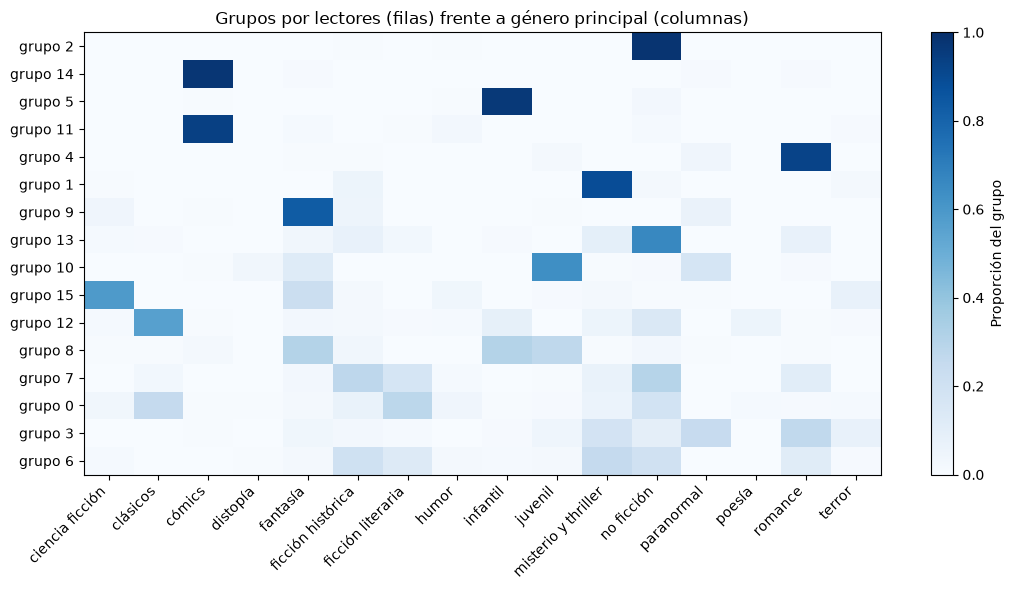

Género más frecuente en todo el dataset: 16.6%


In [11]:
# Mapa de calor: de cada grupo, qué proporción cae en cada género
proporcion = tabla.div(tabla.sum(axis=1), axis=0)
orden = proporcion.max(axis=1).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(proporcion.loc[orden], cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(proporcion.columns)), proporcion.columns, rotation=45, ha="right")
ax.set_yticks(range(len(orden)), [f"grupo {c}" for c in orden])
ax.set_title("Grupos por lectores (filas) frente a género principal (columnas)")
fig.colorbar(im, label="Proporción del grupo")
plt.tight_layout()
plt.show()
print("Género más frecuente en todo el dataset:", f"{pd.Series(genero_real).value_counts(normalize=True).iloc[0]:.1%}")

**Lectura del agrupamiento**

- Con 16 grupos la pureza es **55%**, frente al 17% que daría asignar a todos el
  género más frecuente. ARI 0,29 y NMI 0,48: el comportamiento de los lectores
  recupera buena parte de la clasificación por género, sin haber visto una sola etiqueta.
- **Grupos casi puros:** no ficción de divulgación (98%), manga (97%), infantil
  ilustrado (96%), cómics (94%) y romance contemporáneo (93%). Son públicos muy
  definidos; los cómics se parten en dos grupos, manga por un lado y el resto por otro.
- **Grupos mixtos:** la no ficción se reparte en al menos tres públicos (divulgación
  y negocios, religiosa, memorias junto a ficción histórica), y hay un grupo de
  "club de lectura" que mezcla thriller y ficción histórica reciente (*El ruiseñor*,
  *Big Little Lies*), el mismo cruce que salió en las reglas de libros.
- La silueta es baja (0,13 a 0,23) y sigue subiendo con k: los grupos no están bien
  separados y los datos no señalan un número "correcto" de grupos. k = 16 se eligió
  para comparar con los 16 géneros, no porque sea óptimo.

## 5. Árbol de decisión: ¿se puede predecir el género sin las etiquetas?

Atributos: año de publicación, nota media, cantidad de valoraciones y de ediciones
(en logaritmo), reseñas por valoración, proporción de 5 y de 1 estrella, y si está
en inglés. Se predice el género principal entre los 14 géneros con 100 libros o más.

20% de los libros se reserva como prueba. La profundidad del árbol se elige con
validación cruzada de 5 pliegues sobre el 80% restante.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report

X = atributos_para_arbol(datos)
y = generos["genero_principal"].reindex(X.index)
completos = X.notna().all(axis=1) & y.notna()
frecuencia = y[completos].value_counts()
validos = completos & y.isin(frecuencia[frecuencia >= 100].index)
X, y = X[validos], y[validos]
print(f"Libros: {len(X):,} | géneros: {y.nunique()} | descartados por datos faltantes: {(~completos).sum()}")

X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
busqueda = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"max_depth": [3, 4, 5, 6, 8, 10, 12], "min_samples_leaf": [5, 20, 50]},
    cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="accuracy",
).fit(X_ent, y_ent)
arbol = busqueda.best_estimator_
pred = arbol.predict(X_pru)
base = (y_pru == y_ent.value_counts().index[0]).mean()
print("Mejores hiperparámetros:", busqueda.best_params_, f"| exactitud en validación cruzada: {busqueda.best_score_:.3f}")
print(f"Exactitud en prueba: {accuracy_score(y_pru, pred):.3f} | F1 macro: {f1_score(y_pru, pred, average='macro'):.3f}")
print(f"Línea base (predecir siempre '{y_ent.value_counts().index[0]}'): {base:.3f}")

Libros: 9,886 | géneros: 14 | descartados por datos faltantes: 21


Mejores hiperparámetros: {'max_depth': 10, 'min_samples_leaf': 5} | exactitud en validación cruzada: 0.341
Exactitud en prueba: 0.342 | F1 macro: 0.274
Línea base (predecir siempre 'no ficción'): 0.168


In [13]:
print(classification_report(y_pru, pred, zero_division=0))
pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False).round(3).to_frame("importancia")

                     precision    recall  f1-score   support

    ciencia ficción       0.14      0.10      0.12        86
           clásicos       0.62      0.68      0.65       120
             cómics       0.38      0.30      0.34        76
           fantasía       0.49      0.24      0.32       193
  ficción histórica       0.13      0.10      0.11       126
  ficción literaria       0.22      0.14      0.17       103
              humor       0.00      0.00      0.00        24
           infantil       0.37      0.31      0.33       131
            juvenil       0.27      0.31      0.29       170
misterio y thriller       0.36      0.51      0.42       274
         no ficción       0.31      0.48      0.38       332
         paranormal       0.36      0.37      0.37       106
            romance       0.37      0.31      0.34       199
             terror       0.00      0.00      0.00        38

           accuracy                           0.34      1978
          macro avg   

,importancia
año_publicación,0.254
reseñas_por_valoración,0.159
proporción_5_estrellas,0.151
proporción_1_estrella,0.142
log_valoraciones,0.112
log_ediciones,0.110
nota_media,0.063
en_inglés,0.008


In [14]:
# Un árbol pequeño (profundidad 3) para poder leerlo, impreso como reglas
from sklearn.tree import export_text

arbol_chico = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=42).fit(X_ent, y_ent)
print(f"Exactitud en prueba del árbol de profundidad 3: {accuracy_score(y_pru, arbol_chico.predict(X_pru)):.3f}")
print()
print(export_text(arbol_chico, feature_names=list(X.columns), decimals=2))

Exactitud en prueba del árbol de profundidad 3: 0.275

|--- año_publicación <= 1966.50
|   |--- nota_media <= 3.95
|   |   |--- proporción_1_estrella <= 0.01
|   |   |   |--- class: misterio y thriller
|   |   |--- proporción_1_estrella >  0.01
|   |   |   |--- class: clásicos
|   |--- nota_media >  3.95
|   |   |--- reseñas_por_valoración <= 0.02
|   |   |   |--- class: infantil
|   |   |--- reseñas_por_valoración >  0.02
|   |   |   |--- class: clásicos
|--- año_publicación >  1966.50
|   |--- proporción_1_estrella <= 0.01
|   |   |--- proporción_5_estrellas <= 0.40
|   |   |   |--- class: misterio y thriller
|   |   |--- proporción_5_estrellas >  0.40
|   |   |   |--- class: fantasía
|   |--- proporción_1_estrella >  0.01
|   |   |--- proporción_5_estrellas <= 0.30
|   |   |   |--- class: misterio y thriller
|   |   |--- proporción_5_estrellas >  0.30
|   |   |   |--- class: no ficción



**Lectura del árbol**

- El árbol acierta el **34%** de los géneros en prueba, el doble de la línea base
  (17%), pero lejos de ser útil para clasificar. F1 macro: 0,27.
- Solo los **clásicos** se reconocen bien (F1 0,65), casi todo gracias al año de
  publicación: es el primer corte del árbol (antes o después de 1966) y el atributo
  más importante. Humor y terror no se aciertan nunca.
- Conclusión: el año, la nota y la popularidad dicen poco sobre el tema de un libro.
  Para clasificar por materia hace falta información de contenido o de uso. El
  agrupamiento por lectores de la sección 4 llega a 55% de pureza, aunque esa cifra
  no es comparable de forma directa: se mide sobre los mismos libros que se
  agruparon y no sobre un conjunto de prueba.

## Limitaciones

- **La clasificación de referencia es propia.** Los 16 géneros salen de un
  diccionario de sinónimos hecho a mano sobre etiquetas de lectores; no es Dewey ni
  LCC, y nadie la validó. Otro diccionario daría otros números.
- **Un solo género principal por libro,** aunque la mitad de los libros tiene dos o
  más géneros con peso relevante.
- **Sesgo del dataset:** son los 10.000 libros más populares de Goodreads (casi todos
  en inglés) y usuarios muy activos (entre 19 y 200 valoraciones cada uno). No
  representa a los usuarios de una biblioteca.
- **Valoraciones, no préstamos.** Valorar un libro con 4 estrellas no es lo mismo
  que pedirlo prestado.
- **Umbrales elegidos a mano** (10% para la cesta de géneros, 3% y 2% de soporte,
  k = 16): no se estudió cuánto cambian los resultados al moverlos.